# Why the optimizer surrogates belong among the features
The labels come from SHOP, which allocates a weekly water budget to the most profitable hours. Price features tell the model *which* hours are best, not *how many* hours the plant runs. Two surrogates add that piece: a greedy water-filling that pours the weekly budget into the highest-price hours, and later an LP of the whole cascade.

**This notebook uses no model and no labels to build the surrogates:** only inputs that are known when the case starts. Labels are used only to evaluate them.

**Run:** set `DATA` to the folder with the raw data (searched recursively) and run all cells. The LP section takes a few minutes.

In [1]:
import numpy as np, pandas as pd, yaml, matplotlib.pyplot as plt
from pathlib import Path
from numpy.lib.stride_tricks import sliding_window_view as swv
from sklearn.metrics import roc_auc_score as auc

DATA, T, ETA = Path('.'), 168, 0.88
BLUE, ORANGE, INK = '#2F6DB5', '#C2570C', '#555555'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#E6E6E6', 'font.size': 10})

def read(name, idx='date'):
    d = pd.read_csv(sorted(DATA.rglob(name))[0]); d[idx] = pd.to_datetime(d[idx], utc=True)
    return d.set_index(idx)

PR = read('Historical_day_ahead_price_2015_2025.csv').iloc[:, 0]
IN, VO, WV = [read(f).rename(columns=str.lower) for f in ('Historical_inflow_1958_2025.csv', 'Historical_volume_2015_2024.csv', 'Synthetic_water_value_2015_2024.csv')]
C = pd.concat([read('Constraint_min_flow.csv'), read('Constraint_min_volume.csv')], axis=1)
Y = read('Unit_commitment_decisions.csv', 'starttime').rename(columns=lambda c: c.lower().replace(' ', '_')).sort_index().filter(like='result_committed')
topo = yaml.safe_load(sorted(DATA.rglob('Tokke_Vinje_topology.yaml'))[0].read_text(encoding='utf-8'))['model']

RES = {k.lower(): v for k, v in topo['reservoir'].items()}
PL = {k.lower().replace(' ', '_'): v for k, v in topo['plant'].items()}
PN = {k.lower().replace(' ', '_'): g['p_nom'] for k, g in topo['generator'].items()}
TOPO = {'vesle_kjela': (['kjelavatn'], 'foersvatn'), 'kjela': (['foersvatn', 'bordalsvatn'], 'hyljelihyl'),
        'songa': (['songavatn', 'bitdalsvatn'], 'totak'), 'vinje': (['vaamarvatn', 'totak'], 'vinjevatn'),
        'haukeli': (['langeidvatn', 'vatjern'], 'vinjevatn'), 'tokke': (['vinjevatn'], 'bandak'),
        'byrte': (['botnedalsvatn'], 'byrtevatn'), 'lio': (['byrtevatn'], 'bandak'), 'hogga': (['bandak'], None)}
UP = {'kjela': ['vesle_kjela'], 'vinje': ['kjela', 'songa'], 'tokke': ['vinje', 'haukeli'], 'hogga': ['tokke', 'lio'], 'lio': ['byrte']}
WSRC, CAP_RES = {'vinje': 'totak', 'haukeli': 'langeidvatn'}, {'haukeli': 'vatjern'}
ORDER = ['vesle_kjela', 'songa', 'byrte', 'haukeli', 'kjela', 'lio', 'vinje', 'tokke', 'hogga']  # upstream first
units = sorted({c[len('result_committed_'):].rsplit('_t', 1)[0] for c in Y.columns})
plant_units = {p: [u for u in units if u.rsplit('_g', 1)[0] == p] for p in ORDER}
Yu = {u: Y[[f'result_committed_{u}_t{h}' for h in range(T)]].to_numpy() for u in units}  # (cases, 168)

pos = PR.index.get_indexer(Y.index); assert (pos >= 0).all()
P = swv(PR.to_numpy(), T)[pos]                                         # price (cases, 168)
I = {r: swv(IN[r].reindex(PR.index).to_numpy(), T)[pos] for r in RES}  # inflow (m3/s)
V0 = VO.reindex(Y.index, method='ffill')
WF = WV.reindex(Y.index + pd.Timedelta(days=7), method='ffill').set_axis(Y.index)  # water value at the end of the week
MV = swv(C.reindex(PR.index).fillna(0).to_numpy(), T, axis=0)[pos]
CC = list(C.columns)
print(P.shape, V0.shape, WF.shape)

(2922, 168) (2922, 17) (2922, 17)


## Surrogate
Same logic as `surr` in the short notebooks. For every plant:
- `Wmax`: water available in the week, limited by the turbine capacity;
- `Wmin`: water that must be released to avoid spilling;
- `W`: hours with price above the water value, clipped to `[Wmin, Wmax]`;
- the budget `W` goes to the highest-price hours, giving an estimated number of running units per hour.

In the models the upstream release comes from the stacked predictions. Here it comes from the upstream surrogates, so that no model is needed.

In [2]:
head = lambda r, v: np.interp(v, RES[r]['vol_head']['x'], RES[r]['vol_head']['y'])

def cap(plant):  # max flow of the plant (Mm3/h) from nominal power and head
    up, dn = TOPO[plant]; r0 = CAP_RES.get(plant, up[0])
    hd = head(dn, V0[dn].to_numpy()) if dn else 0
    H = np.maximum(head(r0, V0[r0].to_numpy()) - np.maximum(hd, PL[plant]['outlet_line']), 5)
    return sum(PN[u] for u in plant_units[plant]) / (2.725 * ETA * H)

def surrogate(plant, rel):
    up, c, nu = TOPO[plant][0], cap(plant), len(plant_units[plant])
    V = sum(V0[r].to_numpy() for r in up)
    win = sum(I[r].sum(1) for r in up) * 0.0036 + rel.sum(1)                     # m3/s -> Mm3/h, + upstream release
    mv = sum((MV[:, CC.index(r.capitalize())].max(1) for r in up if r.capitalize() in CC), np.zeros(len(P)))
    Wmax = np.clip(V + win - mv, 0, T * c)
    Wmin = np.minimum(np.maximum(V + win - sum(RES[r]['max_vol'] for r in up), 0), Wmax)
    wv = WF[WSRC.get(plant, up[0])].to_numpy()
    W = np.clip((P > wv[:, None]).sum(1) * c, Wmin, Wmax)
    rank = (-P).argsort(1).argsort(1)
    return np.clip((W / c)[:, None] - rank, 0, 1) * nu, W / c / T, wv             # units per hour, budget (share of the week), water value

S, B, W_, rel = {}, {}, {}, {}
for p in ORDER:
    r = sum((rel[q] for q in UP.get(p, [])), np.zeros_like(P))
    S[p], B[p], W_[p] = surrogate(p, r)
    rel[p] = S[p] / len(plant_units[p]) * cap(p)[:, None]

## Table 1: signal of a single feature, before any model
AUC of three scores used alone, against the unit commitment (2015-2022, all cases):
- **price rank**: rank of the hour inside the week (knows which hours, not how many);
- **log(P / WV)**: price against the water value (also compares the week with the value of the water);
- **surrogate**: estimated running units, also using volumes, inflows and capacity.

The surrogate is almost a step function (full or zero), so its hourly AUC is penalised against a continuous score: it is meant as a feature, not as a predictor. Compare it mainly on the `r` columns.

`r` columns: correlation with the real share of ON hours per week, on non-overlapping weeks (every 7th case). Price rank has no column there because its weekly mean is constant by construction.

In [3]:
rank = P.argsort(1).argsort(1) / (T - 1)
lw = lambda a: np.log(np.clip(a, 1, None))
wk = np.arange(0, len(P), 7)
rows, all_ = {}, {k: ([], []) for k in ('rank', 'wv', 'surr')}
for p in ORDER:
    sc = {'rank': np.broadcast_to(rank, P.shape), 'wv': lw(P) - lw(W_[p])[:, None], 'surr': S[p]}
    on = np.mean([Yu[u] for u in plant_units[p]], 0).mean(1)
    row = {'share ON': on.mean()}
    for k, s in sc.items():
        y, x = zip(*[(Yu[u].ravel(), s.ravel() - (j if k == 'surr' else 0)) for j, u in enumerate(plant_units[p])])
        y, x = np.concatenate(y), np.concatenate(x)
        all_[k][0].append(y); all_[k][1].append(x)
        row[f'AUC {k}'] = auc(y, x) if 0 < y.mean() < 1 else np.nan
    row['r weekly: mean log(P/WV)'] = np.corrcoef(sc['wv'].mean(1)[wk], on[wk])[0, 1]
    row['r weekly: budget'] = np.corrcoef(B[p][wk], on[wk])[0, 1]
    rows[p] = row
t1 = pd.DataFrame(rows).T
t1.loc['all units (micro)'] = {f'AUC {k}': auc(np.concatenate(v[0]), np.concatenate(v[1])) for k, v in all_.items()}
t1.round(3)

,share ON,AUC rank,AUC wv,AUC surr,r weekly: mean log(P/WV),r weekly: budget
vesle_kjela,0.467,0.562,0.986,0.947,0.689,0.970
songa,0.485,0.592,0.972,0.948,0.685,0.945
byrte,0.542,0.563,0.985,0.968,0.656,0.989
haukeli,0.547,0.536,0.856,0.785,0.566,0.621
kjela,0.471,0.593,0.949,0.918,0.646,0.907
lio,0.747,0.576,0.925,0.853,0.548,0.700
vinje,0.388,0.620,0.769,0.764,0.434,0.495
tokke,0.553,0.605,0.892,0.731,0.631,0.437
hogga,0.595,0.589,0.897,0.847,0.567,0.877
all units (micro),NaN,0.589,0.872,0.777,NaN,NaN


## Figure 1: weekly budget against real running time
One point per non-overlapping week; on the diagonal the budget equals the real share of ON hours. The price rank cannot separate these weeks, because its weekly mean is the same every week, and the error analysis of the model without surrogates found that most of the error is at this weekly level.

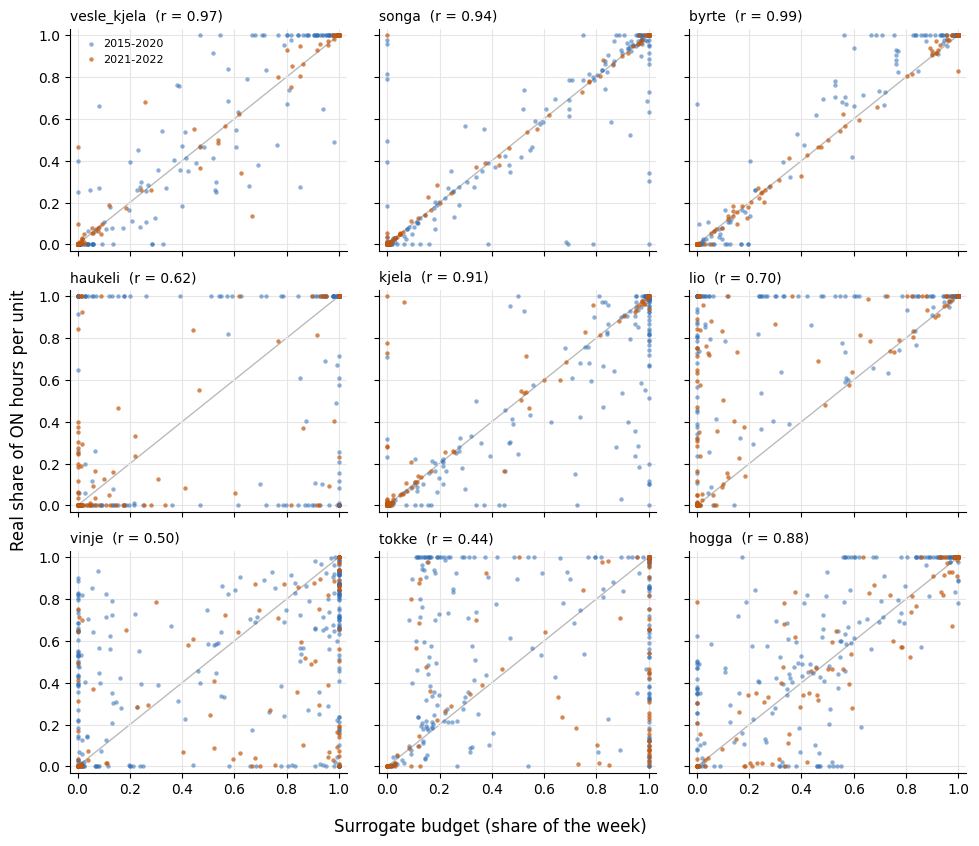

In [4]:
fig, ax = plt.subplots(3, 3, figsize=(10, 8.5), sharex=True, sharey=True)
late = Y.index[wk].year >= 2021
for a, p in zip(ax.ravel(), ORDER):
    on = np.mean([Yu[u] for u in plant_units[p]], 0).mean(1)
    a.plot([0, 1], [0, 1], color='#BBBBBB', lw=1, zorder=1)
    a.scatter(B[p][wk][~late], on[wk][~late], s=10, color=BLUE, alpha=.55, label='2015-2020', zorder=2, lw=0)
    a.scatter(B[p][wk][late], on[wk][late], s=10, color=ORANGE, alpha=.7, label='2021-2022', zorder=3, lw=0)
    a.set_title(f"{p}  (r = {t1.loc[p, 'r weekly: budget']:.2f})", fontsize=10, loc='left')
    a.set_xlim(-.03, 1.03); a.set_ylim(-.03, 1.03)
ax[0, 0].legend(frameon=False, loc='upper left', fontsize=8, handletextpad=.1)
fig.supxlabel('Surrogate budget (share of the week)'); fig.supylabel('Real share of ON hours per unit')
fig.tight_layout(); plt.show()

## Figure 2: one week, how the surrogate works
The week is not hand-picked: it is the 2021-2022 case with the median budget error for Tokke.

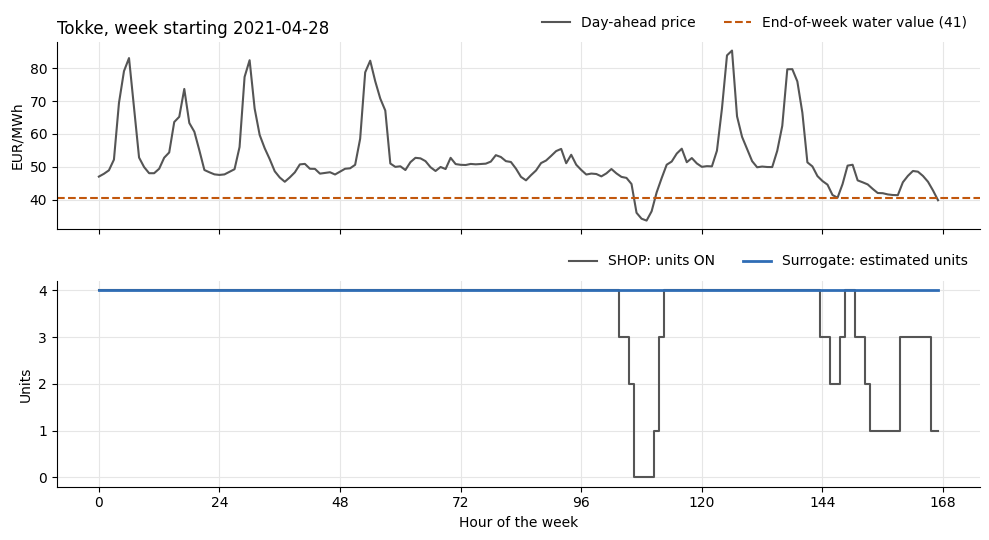

In [5]:
p = 'tokke'; us = plant_units[p]; real = sum(Yu[u] for u in us)
idx = np.where(Y.index.year >= 2021)[0]
err = np.abs(S[p].mean(1) - real.mean(1))[idx]
i = idx[np.argsort(err)[len(err) // 2]]
h = np.arange(T)
fig, (a, b) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, height_ratios=[1, 1.1])
a.plot(h, P[i], color=INK, lw=1.5, label='Day-ahead price')
a.axhline(W_[p][i], color=ORANGE, lw=1.5, ls='--', label=f'End-of-week water value ({W_[p][i]:.0f})')
a.set_ylabel('EUR/MWh'); a.legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1))
a.set_title(f'{p.capitalize()}, week starting {Y.index[i].date()}', loc='left')
b.step(h, real[i], where='mid', color=INK, lw=1.5, label='SHOP: units ON')
b.step(h, S[p][i], where='mid', color=BLUE, lw=2, label='Surrogate: estimated units')
b.set_xlabel('Hour of the week'); b.set_ylabel('Units'); b.set_yticks(range(len(us) + 1)); b.set_xticks(range(0, T + 1, 24))
b.legend(frameon=False, ncol=2, loc='lower right', bbox_to_anchor=(1, 1)); fig.tight_layout(); plt.show()

## Table 2: what the surrogates add to the model
Results of the full runs (same split: first 80% of cases for training, cases after a 7-day gap for test), copied from the outputs of `model_v11` and `model_v12` / `model_v14` / `model_v14_new`.

Only **C -> S** isolates the surrogate. The later steps also change other things, so their gain cannot be attributed to the surrogate alone. Differences between runs of the same model are about 0.0015, so smaller steps are not meaningful.

In [6]:
pd.DataFrame([('C', 'base: price, inflow, volumes, water values, stacking', .9612, .9438),
              ('S', 'C + surrogate dispatch', .9716, .9570),
              ('K', 'S + surrogate corrected by min flow / min volume, constraint features', .9754, .9715),
              ('N', 'K + unscaled prices and water values, Haukeli topology fix', .9780, .9806),
              ('P', 'N + per-unit physics and start/stop costs', .9788, .9823),
              ('L', 'P + LP of the cascade', .9811, .9825)],
             columns=['variant', 'content', 'micro AUC oof', 'micro AUC test']).set_index('variant')

,content,micro AUC oof,micro AUC test
variant,,,
C,"base: price, inflow, volumes, water values, st...",0.9612,0.9438
S,C + surrogate dispatch,0.9716,0.9570
K,S + surrogate corrected by min flow / min volu...,0.9754,0.9715
N,"K + unscaled prices and water values, Haukeli ...",0.9780,0.9806
P,N + per-unit physics and start/stop costs,0.9788,0.9823
L,P + LP of the cascade,0.9811,0.9825


In [7]:
# per plant, C vs S (model_v11)
t2 = pd.DataFrame({'oof C': [.9891, .9721, .9916, .7739, .9603, .9482, .9691, .9678, .9516], 'oof S': [.9913, .9711, .9955, .8586, .9660, .9557, .9693, .9803, .9658],
                   'test C': [.9854, .9635, .9900, .8876, .9811, .8020, .9542, .9323, .9498], 'test S': [.9899, .9379, .9959, .8894, .9728, .8357, .9500, .9703, .9700]},
                  index=['vesle_kjela', 'songa', 'byrte', 'haukeli', 'kjela', 'lio', 'vinje', 'tokke', 'hogga'])
t2['delta oof'], t2['delta test'] = t2['oof S'] - t2['oof C'], t2['test S'] - t2['test C']
t2.round(4)

,oof C,oof S,test C,test S,delta oof,delta test
vesle_kjela,0.9891,0.9913,0.9854,0.9899,0.0022,0.0045
songa,0.9721,0.9711,0.9635,0.9379,-0.0010,-0.0256
byrte,0.9916,0.9955,0.9900,0.9959,0.0039,0.0059
haukeli,0.7739,0.8586,0.8876,0.8894,0.0847,0.0018
kjela,0.9603,0.9660,0.9811,0.9728,0.0057,-0.0083
lio,0.9482,0.9557,0.8020,0.8357,0.0075,0.0337
vinje,0.9691,0.9693,0.9542,0.9500,0.0002,-0.0042
tokke,0.9678,0.9803,0.9323,0.9703,0.0125,0.0380
hogga,0.9516,0.9658,0.9498,0.9700,0.0142,0.0202


## The LP of the cascade
The surrogate looks at one plant at a time and only approximates the water coming from upstream, and the budget often saturates at 0 or 1. The LP removes this limit: one LP per case over the whole cascade (water balances, flow limits, minimum constraints), where each plant earns `price x energy - water value of its own reservoir` and each unit is a flow segment with its marginal efficiency. It gives two features per unit: the LP flow and the reduced cost.

The LP has no on/off variables and no start/stop costs, so it is still a surrogate and not SHOP. It needs no model or labels either.

To limit the time, it is solved only on the non-overlapping weeks (about 0.2 s per case, a few minutes in total).

In [8]:
import scipy.sparse as sp
from scipy.optimize import linprog

GEN = {k.lower().replace(' ', '_'): g for k, g in topo['generator'].items()}
def peak(g):  # flow, reference heads and efficiencies at the peak of the turbine curves
    C_ = g['turb_eff_curves']; b = [int(np.argmax(c['y'])) for c in C_]
    return C_[0]['x'][b[0]], np.array([c['ref'] for c in C_], float), np.array([c['y'][i] / 100 for c, i in zip(C_, b)])

def make_lp():  # same LP as the short notebooks
    K = 0.0036  # 1 m3/s for 1 h = 0.0036 Mm3
    yml = yaml.safe_load(sorted(DATA.rglob('Tokke_Vinje_topology.yaml'))[0].read_text(encoding='utf-8')); m, CON = yml['model'], yml['connections']
    IN_, VO_, WV_, MF, MV_ = [read(f) for f in ('Historical_inflow_1958_2025.csv', 'Historical_volume_2015_2024.csv', 'Synthetic_water_value_2015_2024.csv', 'Constraint_min_flow.csv', 'Constraint_min_volume.csv')]
    RS, PS, RV, TN = list(m['reservoir']), list(m['plant']), list(m['river']), list(m['tunnel'])
    gens = {p: [g for g in m['generator'] if g.rsplit('_G', 1)[0] == p] for p in PS}
    FREE = {'Totak_Vaamarvatn', 'Bordalsvatn_Foersvatn', 'Venemo_Totak'}  # tunnels between reservoirs: flow in both directions
    INTAKE = {'Hogga': 'Bandak', 'Tokke': 'Vinjevatn', 'Lio': 'Byrtevatn', 'Byrte': 'Botnedalsvatn', 'Vinje': 'Vaamarvatn', 'Haukeli': 'Vatjern', 'Songa': 'Songavatn', 'Kjela': 'Foersvatn', 'Vesle Kjela': 'Kjelavatn'}
    OUT = {'Hogga': None, 'Tokke': 'Bandak', 'Lio': 'Bandak', 'Byrte': 'Byrtevatn', 'Vinje': 'Vinjevatn', 'Haukeli': 'Vinjevatn', 'Songa': 'Totak', 'Kjela': 'Hyljelihyl', 'Vesle Kjela': 'Foersvatn'}
    hd = lambda r, v: np.interp(v, m['reservoir'][r]['vol_head']['x'], m['reservoir'][r]['vol_head']['y'])

    def seg(p, v0):  # (marginal MW per m3/s, max flow) of each unit
        pl, dn, out, prev = m['plant'][p], OUT[p], [], 0
        Hg = hd(INTAKE[p], v0[INTAKE[p]]) - max(hd(dn, v0[dn]) if dn else 0, pl['outlet_line'])
        for j, g in enumerate(gens[p]):
            G = m['generator'][g]; q, refs, et = peak(G)
            Hj = max(Hg - float(pl['main_loss'][0]) * ((j + 1) * q)**2 - float(pl['penstock_loss'][G['penstock'] - 1]) * q**2, 1)
            tot = 9.81e-3 * (j + 1) * q * Hj * np.interp(Hj, refs, et) * .98
            out.append(((tot - prev) / q, max(G['turb_eff_curves'][0]['x']))); prev = tot
        return out

    # hourly variables: unit segments | rivers and tunnels | volumes | slacks of the minimum constraints
    segs = [(p, j) for p in PS for j in range(len(gens[p]))]; si = {s: i for i, s in enumerate(segs)}
    Fl = RV + TN; nS, nF = len(segs), len(Fl); fi = {o: nS + i for i, o in enumerate(Fl)}; ri = {r: nS + nF + i for i, r in enumerate(RS)}
    slk = list(MF.columns) + list(MV_.columns); sli = {o: nS + nF + len(RS) + i for i, o in enumerate(slk)}; NV = nS + nF + len(RS) + len(slk)
    at = lambda v, t: v + t * NV
    expr = lambda o: [si[(o, j)] for j in range(len(gens[o]))] if o in m['plant'] else [fi[o]]
    inp, out = {}, {}
    for c in CON:
        a, b = c['from'], c['to']
        if c['from_type'] == 'generator': continue
        if c['to_type'] != 'reservoir' and c['from_type'] == 'reservoir': out.setdefault(a, []).append(b)
        else: inp.setdefault(b, []).append(a)
    # water balances
    R, Cc, Va, n, bal, nodes = [], [], [], 0, [], []
    def add(r, v, x): R.append(r); Cc.append(v); Va.append(x)
    for r in RS:
        for t in range(T):
            add(n, at(ri[r], t), 1.)
            if t: add(n, at(ri[r], t - 1), -1.)
            for o, sg in [(o, -K) for o in inp.get(r, [])] + [(o, K) for o in out.get(r, [])]:
                for v in expr(o): add(n, at(v, t), sg)
            bal.append((n, r, t)); n += 1
    for o in [o for o in inp if o not in m['reservoir']]:
        for t in range(T):
            for v in expr(o): add(n, at(v, t), 1.)
            for u in inp[o]:
                for v in expr(u): add(n, at(v, t), -1.)
            nodes.append((n, o, t)); n += 1
    Aeq = sp.csr_matrix((Va, (R, Cc)), shape=(n, NV * T))
    # minimum constraints with slack
    R, Cc, Va, n, ubk = [], [], [], 0, []
    for o in slk:
        for t in range(T):
            add(n, at(fi[o] if o in fi else ri[o], t), -1.); add(n, at(sli[o], t), -1.); ubk.append((o, t)); n += 1
    Aub = sp.csr_matrix((Va, (R, Cc)), shape=(n, NV * T))

    def solve(ts_):
        p0 = PR.index.get_loc(ts_); P_ = PR.values[p0:p0 + T]; v0 = VO_.loc[ts_]
        wf = WV_.reindex([ts_ + pd.Timedelta(days=7)], method='ffill').iloc[0]
        loc = lambda d: d.iloc[d.index.get_loc(ts_):][:T]
        I_, mf, mv = loc(IN_), loc(MF), loc(MV_)
        c, lo, hi, es = np.zeros(NV * T), np.zeros(NV * T), np.full(NV * T, np.inf), {}
        for p in PS:
            S_ = seg(p, v0)
            for j, (e, cp) in enumerate(S_):
                es[(p, j)] = e; v = at(si[(p, j)], np.arange(T))
                c[v], hi[v] = -(P_ * e - wf[INTAKE[p]] * S_[0][0]), cp  # released water costs the water value of its own reservoir
        for o in RV:
            v = at(fi[o], np.arange(T)); ro = m['river'][o]
            c[v], hi[v] = ro.get('flow_cost_const', 2. if 'flow_cost_curve' in ro else 0.), ro.get('max_flow_const', np.inf)
        for o in TN:
            v = at(fi[o], np.arange(T)); hi[v] = 500
            if o in FREE: lo[v] = -500
        for r in RS: hi[at(ri[r], np.arange(T))] = m['reservoir'][r]['vol_head']['x'][-1]
        for o in slk: c[at(sli[o], np.arange(T))] = 1e4
        b = np.zeros(Aeq.shape[0])
        for row, r, t in bal: b[row] = K * I_[r].values[t] + (float(v0[r]) if t == 0 else 0)
        for row, o, t in nodes:
            if o in I_: b[row] = I_[o].values[t]
        bu = np.array([-(mf[o].values[t] if o in mf else mv[o].values[t]) for o, t in ubk])
        r = linprog(c, A_ub=Aub, b_ub=bu, A_eq=Aeq, b_eq=b, bounds=np.c_[lo, hi], method='highs'); assert r.status == 0, r.message
        rc = r.lower.marginals + r.upper.marginals
        out_ = np.zeros((len(units), 2, T), np.float32)
        for p, j in segs:
            v = at(si[(p, j)], np.arange(T)); u = units.index(gens[p][j].lower().replace(' ', '_'))
            out_[u] = r.x[v] / hi[v], -rc[v] / es[(p, j)]  # relative flow, reduced cost (EUR/MWh)
        return out_
    return solve

solve = make_lp()
LP = np.stack([solve(Y.index[i]) for i in wk])  # (weeks, units, 2, 168)
print(LP.shape)

(418, 14, 2, 168)


## Table 3: signal of the LP, before any model
Same measures as Table 1, on the non-overlapping weeks only. `AUC surr` and `AUC LP` are computed on the same weeks, so they can be compared; the values differ slightly from Table 1, which uses all the cases.

In [9]:
ui = {u: i for i, u in enumerate(units)}
rows, pool = {}, []
for p in ORDER:
    us = plant_units[p]
    on = np.mean([Yu[u] for u in us], 0).mean(1)[wk]
    y = np.concatenate([Yu[u][wk].ravel() for u in us])
    sr = np.concatenate([(S[p][wk] - j).ravel() for j in range(len(us))])
    rc = np.concatenate([LP[:, ui[u], 1].ravel() for u in us])
    flow = np.mean([LP[:, ui[u], 0] for u in us], 0).mean(1)
    rows[p] = {'AUC surr': auc(y, sr), 'AUC LP': auc(y, rc), 'r weekly: budget': np.corrcoef(B[p][wk], on)[0, 1], 'r weekly: LP flow': np.corrcoef(flow, on)[0, 1]}
    pool.append((y, sr, rc))
t3 = pd.DataFrame(rows).T
y_, s_, r_ = [np.concatenate([x[k] for x in pool]) for k in range(3)]
t3.loc['all units (micro)'] = {'AUC surr': auc(y_, s_), 'AUC LP': auc(y_, r_)}
t3.round(3)

,AUC surr,AUC LP,r weekly: budget,r weekly: LP flow
vesle_kjela,0.944,0.984,0.970,0.970
songa,0.951,0.978,0.945,0.953
byrte,0.968,0.991,0.989,0.977
haukeli,0.780,0.891,0.621,0.757
kjela,0.920,0.961,0.907,0.927
lio,0.856,0.919,0.700,0.718
vinje,0.757,0.778,0.495,0.602
tokke,0.711,0.922,0.437,0.858
hogga,0.844,0.920,0.877,0.860
all units (micro),0.774,0.900,NaN,NaN


## Figure 3: surrogate budget and LP flow on the weakest plants
The four plants where the budget has the lowest correlation with the real running time.

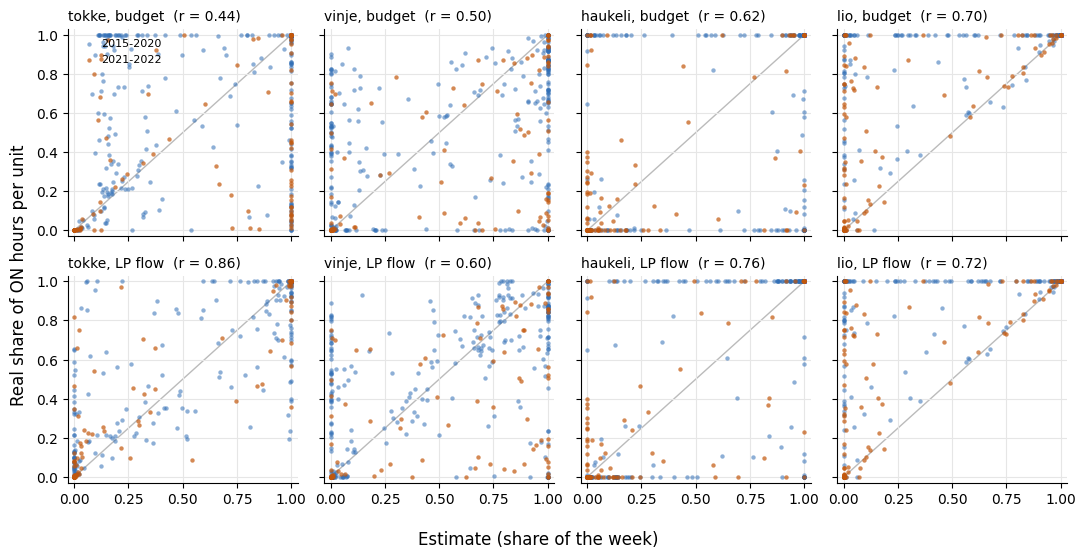

In [10]:
weak = t3.drop('all units (micro)')['r weekly: budget'].sort_values().index[:4]
fig, ax = plt.subplots(2, 4, figsize=(11, 5.6), sharex=True, sharey=True)
for k, p in enumerate(weak):
    on = np.mean([Yu[u] for u in plant_units[p]], 0).mean(1)[wk]
    flow = np.mean([LP[:, ui[u], 0] for u in plant_units[p]], 0).mean(1)
    for a, x, name, col in ((ax[0, k], B[p][wk], 'budget', 'r weekly: budget'), (ax[1, k], flow, 'LP flow', 'r weekly: LP flow')):
        a.plot([0, 1], [0, 1], color='#BBBBBB', lw=1, zorder=1)
        a.scatter(x[~late], on[~late], s=10, color=BLUE, alpha=.55, label='2015-2020', zorder=2, lw=0)
        a.scatter(x[late], on[late], s=10, color=ORANGE, alpha=.7, label='2021-2022', zorder=3, lw=0)
        a.set_title(f'{p}, {name}  (r = {t3.loc[p, col]:.2f})', fontsize=10, loc='left')
        a.set_xlim(-.03, 1.03); a.set_ylim(-.03, 1.03)
ax[0, 0].legend(frameon=False, loc='upper left', fontsize=8, handletextpad=.1)
fig.supxlabel('Estimate (share of the week)'); fig.supylabel('Real share of ON hours per unit')
fig.tight_layout(); plt.show()

## Table 4: what the LP adds to the model
Results of the full run, copied from the output of `model_v14_new`. Used alone, the LP reduced cost reaches a micro AUC of 0.8950 on the test set.

On the micro AUC the LP adds 0.0023 on OOF and 0.0002 on test, and the test gain is within the difference between runs. The main effect is on Haukeli, the weakest plant, while Songa gets worse on test.

In [11]:
t4 = pd.DataFrame({'oof P': [.9932, .9766, .9953, .8737, .9629, .9674, .9774, .9886, .9705], 'oof L': [.9933, .9764, .9953, .9189, .9700, .9703, .9777, .9882, .9706],
                   'test P': [.9941, .9874, .9983, .8983, .9801, .9397, .9836, .9904, .9792], 'test L': [.9946, .9803, .9981, .9227, .9799, .9421, .9843, .9906, .9802]},
                  index=['vesle_kjela', 'songa', 'byrte', 'haukeli', 'kjela', 'lio', 'vinje', 'tokke', 'hogga'])
t4['delta oof'], t4['delta test'] = t4['oof L'] - t4['oof P'], t4['test L'] - t4['test P']
t4.round(4)

,oof P,oof L,test P,test L,delta oof,delta test
vesle_kjela,0.9932,0.9933,0.9941,0.9946,0.0001,0.0005
songa,0.9766,0.9764,0.9874,0.9803,-0.0002,-0.0071
byrte,0.9953,0.9953,0.9983,0.9981,0.0000,-0.0002
haukeli,0.8737,0.9189,0.8983,0.9227,0.0452,0.0244
kjela,0.9629,0.9700,0.9801,0.9799,0.0071,-0.0002
lio,0.9674,0.9703,0.9397,0.9421,0.0029,0.0024
vinje,0.9774,0.9777,0.9836,0.9843,0.0003,0.0007
tokke,0.9886,0.9882,0.9904,0.9906,-0.0004,0.0002
hogga,0.9705,0.9706,0.9792,0.9802,0.0001,0.0010
